# Classificação de Células Sanguíneas com CNNs — BloodMNIST

**UniRV — Faculdade de Engenharia de Software · Disciplina: Redes Neurais · Prof. Sandro S. Moreira**

**Aluno:** Marques Vinicius Melo Martins

Este notebook é, ao mesmo tempo, o **pipeline executável** (download oficial via `medmnist` → pré-processamento → treino → validação → teste) e o **relatório técnico** da atividade. As seções do relatório estão marcadas com 📄.

| Seção | Conteúdo |
|---|---|
| 0 | Configuração, seed e reprodutibilidade |
| 1 📄 | Análise Exploratória dos Dados |
| 2 | Pipeline de dados (augmentation, normalização, loaders) |
| 3 📄 | Estratégia de balanceamento (com ablação) |
| 4 📄 | Decisão arquitetural (CustomCNN × ResNet18) |
| 5 📄 | Otimização e regularização (busca de hiperparâmetros) |
| 6 | Transfer learning com ResNet18 |
| 7 📄 | Resultados e métricas no teste oficial |
| 8 📄 | Discussão de erros |
| 9 📄 | Conclusão |

**Como executar:** no Google Colab, `Ambiente de execução → Alterar o tipo de ambiente de execução → GPU (T4)` e depois `Ambiente de execução → Executar tudo`. A métrica oficial é o **Macro F1-Score** no conjunto de teste.

## 0. Configuração e reprodutibilidade

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist"], check=True)

# Necessário para algoritmos determinísticos do cuBLAS (GPU)
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

':4096:8'

In [2]:
import copy, json, random, shutil, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models
from torchvision.transforms import v2
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report

import medmnist
from medmnist import INFO

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
print(f"torch {torch.__version__} | medmnist {medmnist.__version__} | Colab: {IN_COLAB}")

torch 2.11.0+cu130 | medmnist 3.0.2 | Colab: True


Todos os hiperparâmetros ficam centralizados em `CFG`. A flag `quick` liga um **modo rápido** (poucos dados e 1–2 épocas) usado apenas para testar o código localmente em CPU; a execução oficial (Colab, GPU) usa `quick=False`.

In [3]:
QUICK = os.environ.get("BLOOD_QUICK", "0") == "1"   # modo rápido só para depuração local

CFG = dict(
    quick=QUICK,
    seed=42,
    batch_size=128,
    num_workers=2 if os.name != "nt" else 0,   # Windows + notebook não suporta workers
    # CustomCNN
    cnn_epochs=30,
    cnn_widths=(64, 128, 256),
    cnn_dropout=0.3,
    # ResNet18 (transfer learning)
    resnet_epochs=20,
    resnet_img_size=128,
    resnet_lr=3e-4,
    resnet_wd=0.05,
    # regularização / treino
    label_smoothing=0.1,
    patience=8,              # early stopping (épocas sem melhorar o Macro F1 de validação)
    # tamanho dos subconjuntos no modo rápido
    quick_train=600, quick_eval=300,
)
if CFG["quick"]:
    CFG.update(cnn_epochs=2, resnet_epochs=1, patience=2)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"   # precisão mista: mais rápido na GPU
OUT = Path("outputs"); (OUT / "figures").mkdir(parents=True, exist_ok=True); (OUT / "checkpoints").mkdir(exist_ok=True)

def seed_everything(seed: int):
    """Fixa todas as fontes de aleatoriedade para garantir reprodutibilidade."""
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

seed_everything(CFG["seed"])
print("Dispositivo:", DEVICE, "| AMP:", USE_AMP, "| modo rápido:", CFG["quick"])
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Dispositivo: cuda | AMP: True | modo rápido: False
GPU: Tesla T4


## 1. 📄 Análise Exploratória dos Dados

Carregamento **oficial** pela biblioteca `medmnist`, exatamente como no enunciado. Os três *splits* oficiais (train / val / test) são usados separadamente: o treino ajusta os pesos, a validação escolhe modelos e hiperparâmetros, e o teste é usado **apenas na avaliação final**.

In [4]:
data_flag = "bloodmnist"
info = INFO[data_flag]
DataClass = getattr(medmnist, info["python_class"])

train_dataset = DataClass(split="train", download=True)
val_dataset = DataClass(split="val", download=True)
test_dataset = DataClass(split="test", download=True)

print(f"Número de classes: {len(info['label'])}")
print(f"Rótulos oficiais: {info['label']}")

X = {s: d.imgs for s, d in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]}
Y = {s: d.labels.ravel().astype(np.int64) for s, d in [("train", train_dataset), ("val", val_dataset), ("test", test_dataset)]}
for s in X:
    print(f"{s:>5}: {X[s].shape}  dtype={X[s].dtype}")

CLASSES = ["Basófilo", "Eosinófilo", "Eritroblasto", "Granulócito imaturo",
           "Linfócito", "Monócito", "Neutrófilo", "Plaqueta"]
N_CLASSES = len(CLASSES)

100%|██████████| 35.5M/35.5M [00:35<00:00, 989kB/s] 


Número de classes: 8
Rótulos oficiais: {'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}
train: (11959, 28, 28, 3)  dtype=uint8
  val: (1712, 28, 28, 3)  dtype=uint8
 test: (3421, 28, 28, 3)  dtype=uint8


,train,val,test,% treino
Basófilo,852,122,244,7.1
Eosinófilo,2181,312,624,18.2
Eritroblasto,1085,155,311,9.1
Granulócito imaturo,2026,290,579,16.9
Linfócito,849,122,243,7.1
Monócito,993,143,284,8.3
Neutrófilo,2330,333,666,19.5
Plaqueta,1643,235,470,13.7


Razão de desbalanceamento (maior/menor classe no treino): 2.74x


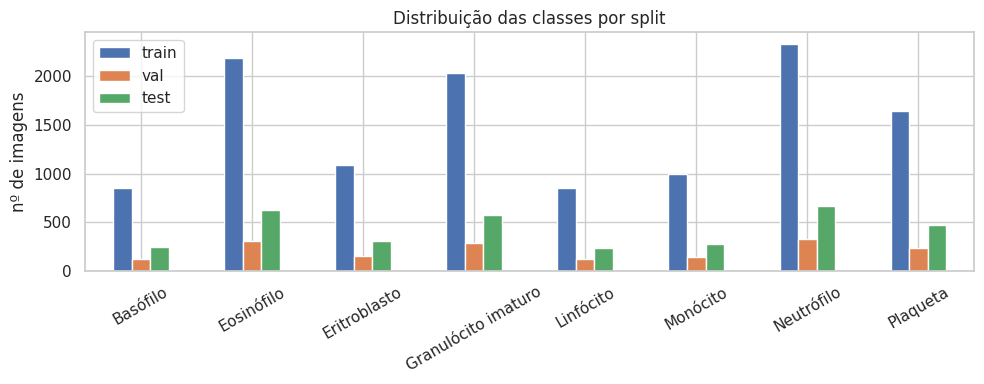

In [5]:
counts = pd.DataFrame({s: np.bincount(Y[s], minlength=N_CLASSES) for s in ["train", "val", "test"]}, index=CLASSES)
counts["% treino"] = (100 * counts["train"] / counts["train"].sum()).round(1)
imbalance_ratio = counts["train"].max() / counts["train"].min()
display(counts)
print(f"Razão de desbalanceamento (maior/menor classe no treino): {imbalance_ratio:.2f}x")

fig, ax = plt.subplots(figsize=(10, 4))
counts[["train", "val", "test"]].plot.bar(ax=ax)
ax.set_title("Distribuição das classes por split"); ax.set_ylabel("nº de imagens"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(OUT / "figures/distribuicao_classes.png", dpi=150); plt.show()

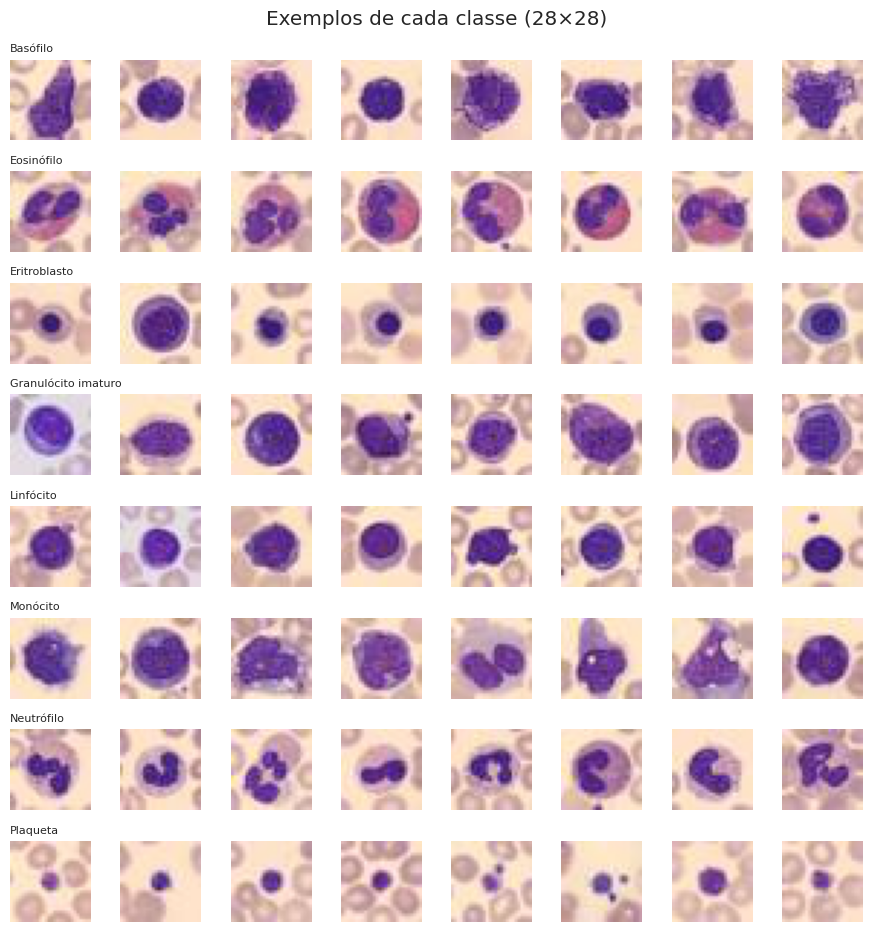

In [6]:
rng = np.random.default_rng(CFG["seed"])
fig, axes = plt.subplots(N_CLASSES, 8, figsize=(9, 9.5))
for c in range(N_CLASSES):
    idx = rng.choice(np.where(Y["train"] == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X["train"][i]); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.suptitle("Exemplos de cada classe (28×28)"); plt.tight_layout()
plt.savefig(OUT / "figures/exemplos_classes.png", dpi=150); plt.show()

In [7]:
# Estatísticas de cor (calculadas SOMENTE no treino, usadas na normalização da CustomCNN)
TRAIN_MEAN = (X["train"] / 255.0).mean(axis=(0, 1, 2))
TRAIN_STD = (X["train"] / 255.0).std(axis=(0, 1, 2))
print("Média RGB (treino):", TRAIN_MEAN.round(4), "| Desvio RGB (treino):", TRAIN_STD.round(4))

Média RGB (treino): [0.7943 0.6597 0.6962] | Desvio RGB (treino): [0.2156 0.2416 0.1179]


**Observações e desafios:**

- **Desbalanceamento moderado:** a maior classe (Neutrófilo) tem cerca de 2,7× mais imagens que as menores (Linfócito e Basófilo). Não é extremo, mas sem tratamento o modelo tende a favorecer as classes grandes, o que derruba o **Macro F1** (que pesa todas as 8 classes igualmente). A proporção entre classes é praticamente a mesma nos três splits.
- **Baixa resolução (28×28):** detalhes como granulação do citoplasma e formato do núcleo — que diferenciam, por exemplo, *granulócitos imaturos*, *neutrófilos* e *monócitos* — ficam com poucos pixels.
- **Classes morfologicamente parecidas:** granulócitos imaturos são precursores dos neutrófilos e compartilham núcleo grande/irregular com monócitos; espera-se que a maior parte da confusão do modelo ocorra entre essas três classes.
- **Orientação arbitrária:** uma célula rotacionada continua sendo a mesma célula, o que justifica rotações e espelhamentos como *data augmentation*.
- **Variação de coloração** entre lâminas (tons de rosa/roxo) → leve *color jitter*.
- Observação: o enunciado lista "mielócitos" entre as classes, mas os rótulos oficiais do BloodMNIST trazem **linfócito** como classe 4, e os mielócitos fazem parte da classe 3 (*granulócitos imaturos*). Usamos os rótulos oficiais.

## 2. Pipeline de dados

- **Treino:** rotações de 90° + espelhamento (simetrias exatas, sem perda de pixels), leve transformação afim (±15°, deslocamento de 5%, escala 0,9–1,1) e leve *color jitter*.
- **Validação/Teste:** nenhuma augmentation — apenas conversão para tensor.
- A **normalização** e o **redimensionamento** ficam dentro de cada modelo (módulo `Preprocess`), assim os dois modelos compartilham exatamente os mesmos *DataLoaders*.

In [8]:
class RandomRot90(nn.Module):
    """Rotação aleatória em múltiplos de 90° (células não têm orientação preferencial)."""
    def forward(self, x):
        k = int(torch.randint(0, 4, (1,)))
        return torch.rot90(x, k, dims=(-2, -1))

train_tf = v2.Compose([
    v2.ToImage(), v2.ToDtype(torch.float32, scale=True),
    RandomRot90(),
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=15, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=[float(m) for m in TRAIN_MEAN]),
    v2.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
])
eval_tf = v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])

class BloodDataset(Dataset):
    def __init__(self, imgs, labels, transform):
        self.imgs, self.labels, self.transform = imgs, labels, transform
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        return self.transform(self.imgs[i]), int(self.labels[i])

def maybe_subset(x, y, n):
    """No modo rápido usa só uma amostra dos dados (para testar o código)."""
    if not CFG["quick"]:
        return x, y
    idx = np.random.default_rng(CFG["seed"]).choice(len(y), n, replace=False)
    return x[idx], y[idx]

Xtr, Ytr = maybe_subset(X["train"], Y["train"], CFG["quick_train"])
Xva, Yva = maybe_subset(X["val"], Y["val"], CFG["quick_eval"])
Xte, Yte = maybe_subset(X["test"], Y["test"], CFG["quick_eval"])

ds_train = BloodDataset(Xtr, Ytr, train_tf)
ds_val = BloodDataset(Xva, Yva, eval_tf)
ds_test = BloodDataset(Xte, Yte, eval_tf)

def make_loader(ds, shuffle=False, sampler=None):
    g = torch.Generator(); g.manual_seed(CFG["seed"])
    return DataLoader(ds, batch_size=CFG["batch_size"], shuffle=shuffle and sampler is None, sampler=sampler,
                      num_workers=CFG["num_workers"], worker_init_fn=seed_worker, generator=g,
                      pin_memory=DEVICE.type == "cuda")

val_loader = make_loader(ds_val)
test_loader = make_loader(ds_test)
print(f"treino={len(ds_train)} | val={len(ds_val)} | teste={len(ds_test)}")

treino=11959 | val=1712 | teste=3421


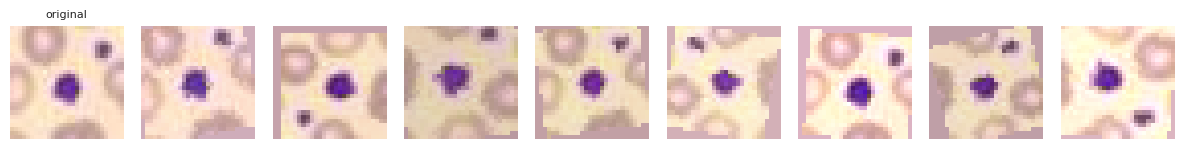

In [9]:
# Visualização da augmentation: mesma imagem, 8 versões aumentadas
torch.manual_seed(0)
fig, axes = plt.subplots(1, 9, figsize=(12, 1.8))
axes[0].imshow(Xtr[0]); axes[0].set_title("original", fontsize=8)
for j in range(1, 9):
    axes[j].imshow(train_tf(Xtr[0]).permute(1, 2, 0).clamp(0, 1).numpy())
for a in axes: a.axis("off")
plt.tight_layout(); plt.savefig(OUT / "figures/augmentation.png", dpi=150); plt.show()
seed_everything(CFG["seed"])

## 3. 📄 Estratégia de balanceamento

Duas frentes, como pede o enunciado:

1. **Nível de dados:** *data augmentation* específica para microscopia (seção 2) e, como alternativa testada, **reamostragem ponderada** (`WeightedRandomSampler`): cada imagem é sorteada com probabilidade inversamente proporcional ao tamanho da sua classe, de modo que cada *batch* fica aproximadamente balanceado.
2. **Nível de algoritmo:** **CrossEntropy ponderada** — o erro em classes raras "custa mais". Usamos peso $w_c \propto 1/\sqrt{n_c}$ (normalizado para média 1). A raiz quadrada suaviza a correção: como o desbalanceamento é moderado (2,7×), o peso inverso puro super-corrigiria e prejudicaria a precisão das classes grandes.

Em todas as variantes usamos **label smoothing = 0,1** (regularização: o alvo vira 0,9 na classe correta e 0,1 distribuído entre as demais, reduzindo excesso de confiança).

Para decidir **com dados** e não só por intuição, treinamos a CustomCNN com três estratégias (mesmos demais hiperparâmetros) e comparamos o Macro F1 na **validação**:

| Estratégia | Loss | Amostragem |
|---|---|---|
| `none` | CE + smoothing | aleatória uniforme |
| `weighted` | CE **ponderada** + smoothing | aleatória uniforme |
| `sampler` | CE + smoothing | **WeightedRandomSampler** |

In [10]:
train_counts = np.bincount(Y["train"], minlength=N_CLASSES)   # contagem do treino completo
class_w = 1.0 / np.sqrt(train_counts)
class_w = class_w / class_w.mean()
CLASS_WEIGHTS = torch.tensor(class_w, dtype=torch.float32)
display(pd.DataFrame({"n_treino": train_counts, "peso_loss": class_w.round(3)}, index=CLASSES))

sample_w = (1.0 / train_counts)[Ytr]
train_sampler = WeightedRandomSampler(torch.tensor(sample_w, dtype=torch.double), num_samples=len(Ytr),
                                      replacement=True, generator=torch.Generator().manual_seed(CFG["seed"]))

def make_loss(balance):
    w = CLASS_WEIGHTS.to(DEVICE) if balance == "weighted" else None
    return nn.CrossEntropyLoss(weight=w, label_smoothing=CFG["label_smoothing"])

def make_train_loader(balance):
    return make_loader(ds_train, sampler=train_sampler) if balance == "sampler" else make_loader(ds_train, shuffle=True)

,n_treino,peso_loss
Basófilo,852,1.248
Eosinófilo,2181,0.780
Eritroblasto,1085,1.106
Granulócito imaturo,2026,0.809
Linfócito,849,1.250
Monócito,993,1.156
Neutrófilo,2330,0.754
Plaqueta,1643,0.898


## 4. 📄 Decisão arquitetural

### 4.1 CustomCNN (do zero)

Rede residual compacta, pensada para imagens 28×28:

```
entrada 3×28×28 → Normalização (média/desvio do treino)
Stem: Conv3×3(64) + BN + ReLU                         28×28
Estágio 1: Bloco residual(64)   → MaxPool            14×14
Estágio 2: Bloco residual(128)  → MaxPool             7×7
Estágio 3: Bloco residual(256)
Global Average Pooling → Dropout(0,3) → Linear(8)
Bloco residual = Conv3×3 + BN + ReLU + Conv3×3 + BN  (+ atalho)  → ReLU
```

**Justificativas:**
- **Convoluções 3×3** em sequência capturam padrões locais (bordas, textura do citoplasma, formato do núcleo) com poucos parâmetros.
- **Blocos residuais** (atalho $y = F(x) + x$) facilitam o fluxo do gradiente e permitem treinar mais rápido e de forma mais estável.
- **Batch Normalization** estabiliza a distribuição das ativações, permitindo *learning rates* maiores, e tem leve efeito regularizador.
- **Apenas 2 poolings:** a imagem já é pequena; reduzir demais (para 3×3 ou 1×1) destruiria informação espacial.
- **Global Average Pooling** no lugar de camadas densas grandes reduz parâmetros e overfitting.
- **Dropout** antes do classificador como regularização adicional.

### 4.2 ResNet18 pré-treinada (transfer learning)

- Backbone **ResNet18 pré-treinado no ImageNet** (1,2 milhão de imagens naturais): os filtros iniciais (bordas, cores, texturas) são genéricos e reaproveitáveis.
- A ResNet18 foi projetada para 224×224: com 28×28 sua primeira etapa (conv stride 2 + maxpool) reduziria a imagem a 7×7 logo de início. Por isso fazemos **upsampling bilinear 28→128** dentro do modelo e normalizamos com as estatísticas do ImageNet, mantendo **todas** as camadas pré-treinadas intactas.
- A última camada (1000 classes) é trocada por `Dropout(0,2) + Linear(512, 8)`; fazemos **fine-tuning completo** com *learning rate* baixo (3e-4) para não destruir os pesos pré-treinados.

In [11]:
class Preprocess(nn.Module):
    """Normalização (e redimensionamento opcional) dentro do modelo."""
    def __init__(self, mean, std, size=None):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean, dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std, dtype=torch.float32).view(1, 3, 1, 1))
        self.size = size
    def forward(self, x):
        if self.size is not None:
            x = F.interpolate(x, size=(self.size, self.size), mode="bilinear", align_corners=False)
        return (x - self.mean) / self.std

class ResBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
        )
        self.shortcut = (nn.Identity() if cin == cout else
                         nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout)))
    def forward(self, x):
        return F.relu(self.body(x) + self.shortcut(x))

class CustomCNN(nn.Module):
    def __init__(self, widths=(64, 128, 256), dropout=0.3, n_classes=8):
        super().__init__()
        w1, w2, w3 = widths
        self.pre = Preprocess(TRAIN_MEAN, TRAIN_STD)
        self.features = nn.Sequential(
            nn.Conv2d(3, w1, 3, padding=1, bias=False), nn.BatchNorm2d(w1), nn.ReLU(inplace=True),
            ResBlock(w1, w1), nn.MaxPool2d(2),     # 28 → 14
            ResBlock(w1, w2), nn.MaxPool2d(2),     # 14 → 7
            ResBlock(w2, w3),
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        )
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(w3, n_classes))
    def forward(self, x):
        return self.head(self.features(self.pre(x)))

def build_resnet18():
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    m.fc = nn.Sequential(nn.Dropout(0.2), nn.Linear(m.fc.in_features, N_CLASSES))
    return nn.Sequential(Preprocess([0.485, 0.456, 0.406], [0.229, 0.224, 0.225], size=CFG["resnet_img_size"]), m)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

print(f"CustomCNN: {n_params(CustomCNN(CFG['cnn_widths'])):,} parâmetros")
print(f"ResNet18 : {n_params(build_resnet18()):,} parâmetros")

CustomCNN: 1,227,080 parâmetros
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 217MB/s]

ResNet18 : 11,180,616 parâmetros


### Funções de treino e avaliação (compartilhadas pelos dois modelos)

- `predict`: retorna probabilidades; opcionalmente com **TTA** (*test-time augmentation*: média das previsões sobre as 8 simetrias de rotação/espelhamento da imagem).
- `fit`: laço de treino com **early stopping** pelo Macro F1 de validação e **checkpoint do melhor modelo** (o modelo final é o da melhor época na validação, nunca escolhido pelo teste).
- A loss reportada em validação/teste é a **CrossEntropy padrão** (sem pesos e sem smoothing), comparável ao critério de desempate do ranking.

In [12]:
def dihedral(x, k):
    """k ∈ 0..7: 4 rotações × (com/sem espelhamento)."""
    x = torch.rot90(x, k % 4, dims=(-2, -1))
    return torch.flip(x, dims=(-1,)) if k >= 4 else x

@torch.no_grad()
def predict(model, loader, tta=False):
    model.eval()
    probs, ys = [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
            if tta:
                p = torch.stack([F.softmax(model(dihedral(x, k)).float(), 1) for k in range(8)]).mean(0)
            else:
                p = F.softmax(model(x).float(), 1)
        probs.append(p.cpu()); ys.append(y)
    probs, ys = torch.cat(probs), torch.cat(ys)
    loss = F.nll_loss(torch.log(probs.clamp_min(1e-12)), ys).item()
    preds = probs.argmax(1).numpy()
    return dict(loss=loss, probs=probs.numpy(), preds=preds, y=ys.numpy(),
                macro_f1=f1_score(ys, preds, average="macro"), acc=accuracy_score(ys, preds))

def make_optimizer(model, name, lr, wd):
    if name == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    if name == "sgd":
        return torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=wd)
    raise ValueError(name)

def fit(model, name, train_loader, loss_fn, optim="adamw", lr=1e-3, wd=0.05, sched="cosine", epochs=30):
    model = model.to(DEVICE)
    opt = make_optimizer(model, optim, lr, wd)
    if sched == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    else:
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.3, patience=3)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    best_f1, best_state, best_epoch, wait, hist = -1, None, 0, 0, []
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        tot_loss, preds, ys = 0.0, [], []
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                out = model(x); loss = loss_fn(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot_loss += loss.item() * len(y); preds.append(out.argmax(1).cpu()); ys.append(y.cpu())
        preds, ys = torch.cat(preds), torch.cat(ys)
        val = predict(model, val_loader)
        lr_now = opt.param_groups[0]["lr"]
        scheduler.step(val["macro_f1"]) if sched == "plateau" else scheduler.step()
        hist.append(dict(epoch=ep, train_loss=tot_loss / len(ys), train_f1=f1_score(ys, preds, average="macro"),
                         val_loss=val["loss"], val_f1=val["macro_f1"], val_acc=val["acc"], lr=lr_now))
        improved = val["macro_f1"] > best_f1
        if improved:
            best_f1, best_epoch, wait = val["macro_f1"], ep, 0
            best_state = copy.deepcopy({k: v.detach().cpu() for k, v in model.state_dict().items()})
        else:
            wait += 1
        print(f"[{name}] ep {ep:02d} | train loss {hist[-1]['train_loss']:.4f} F1 {hist[-1]['train_f1']:.4f} | "
              f"val loss {val['loss']:.4f} F1 {val['macro_f1']:.4f} {'*' if improved else ''}")
        if wait >= CFG["patience"]:
            print(f"[{name}] early stopping na época {ep} (melhor: época {best_epoch})")
            break
    model.load_state_dict(best_state)
    torch.save(best_state, OUT / f"checkpoints/{name}.pt")
    hist = pd.DataFrame(hist); hist.to_csv(OUT / f"history_{name}.csv", index=False)
    summary = dict(run=name, optim=optim, lr=lr, wd=wd, sched=sched, best_epoch=best_epoch,
                   epochs_run=len(hist), val_macro_f1=best_f1, train_time_s=time.time() - t0)
    return model, hist, summary

def plot_history(hist, title, fname):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(hist.epoch, hist.train_loss, label="treino (loss de treino*)"); ax[0].plot(hist.epoch, hist.val_loss, label="validação")
    ax[0].set_title(f"{title} — loss"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(hist.epoch, hist.train_f1, label="treino"); ax[1].plot(hist.epoch, hist.val_f1, label="validação")
    ax[1].set_title(f"{title} — Macro F1"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout(); plt.savefig(OUT / f"figures/{fname}.png", dpi=150); plt.show()

### 3.1 Ablação das estratégias de balanceamento (CustomCNN, AdamW lr=1e-3, Cosine)

In [13]:
RUNS, MODELS, HISTS = [], {}, {}

def run_cnn(name, balance, optim="adamw", lr=1e-3, wd=None, sched="cosine"):
    seed_everything(CFG["seed"])
    wd = wd if wd is not None else (0.05 if optim == "adamw" else 5e-4)
    model = CustomCNN(CFG["cnn_widths"], CFG["cnn_dropout"], N_CLASSES)
    model, hist, s = fit(model, name, make_train_loader(balance), make_loss(balance),
                         optim=optim, lr=lr, wd=wd, sched=sched, epochs=CFG["cnn_epochs"])
    s.update(model="CustomCNN", balance=balance)
    RUNS.append(s); MODELS[name] = model; HISTS[name] = hist
    return s

for b in ["none", "weighted", "sampler"]:
    run_cnn(f"cnn_bal-{b}", b)

ablation = pd.DataFrame(RUNS)[["run", "balance", "best_epoch", "val_macro_f1", "train_time_s"]]
display(ablation.round(4))
BEST_BALANCE = ablation.loc[ablation.val_macro_f1.idxmax(), "balance"]
print("Estratégia de balanceamento escolhida (maior Macro F1 de validação):", BEST_BALANCE)

[cnn_bal-none] ep 01 | train loss 0.9972 F1 0.7119 | val loss 0.6728 F1 0.6569 *
[cnn_bal-none] ep 02 | train loss 0.8250 F1 0.8119 | val loss 0.7688 F1 0.6761 *
[cnn_bal-none] ep 03 | train loss 0.7494 F1 0.8636 | val loss 0.4016 F1 0.8656 *
[cnn_bal-none] ep 04 | train loss 0.7241 F1 0.8790 | val loss 0.3599 F1 0.8787 *
[cnn_bal-none] ep 05 | train loss 0.7037 F1 0.8884 | val loss 0.4736 F1 0.8190 
[cnn_bal-none] ep 06 | train loss 0.6892 F1 0.8952 | val loss 0.5389 F1 0.8125 
[cnn_bal-none] ep 07 | train loss 0.6779 F1 0.9002 | val loss 0.2951 F1 0.9105 *
[cnn_bal-none] ep 08 | train loss 0.6576 F1 0.9154 | val loss 0.5061 F1 0.7804 
[cnn_bal-none] ep 09 | train loss 0.6530 F1 0.9145 | val loss 0.2638 F1 0.9305 *
[cnn_bal-none] ep 10 | train loss 0.6380 F1 0.9275 | val loss 0.2620 F1 0.9071 
[cnn_bal-none] ep 11 | train loss 0.6361 F1 0.9228 | val loss 0.2327 F1 0.9462 *
[cnn_bal-none] ep 12 | train loss 0.6272 F1 0.9323 | val loss 0.2916 F1 0.9102 
[cnn_bal-none] ep 13 | train loss

,run,balance,best_epoch,val_macro_f1,train_time_s
0,cnn_bal-none,none,26,0.9696,520.8943
1,cnn_bal-weighted,weighted,24,0.9702,519.8346
2,cnn_bal-sampler,sampler,27,0.9704,522.6104


Estratégia de balanceamento escolhida (maior Macro F1 de validação): sampler


**Interpretação da ablação**

| Estratégia | Macro F1 (validação) |
|---|---|
| `none` (sem tratamento) | 0,9696 |
| `weighted` (CE ponderada) | 0,9702 |
| `sampler` (WeightedRandomSampler) | **0,9704** |

- As duas estratégias de balanceamento superaram a linha de base sem tratamento, e o `WeightedRandomSampler` foi a melhor. Por isso ele foi usado em todos os experimentos seguintes, incluindo a ResNet18.
- A diferença, porém, é **pequena** (≈0,001 de Macro F1, o equivalente a 1–2 imagens da validação). Isso é coerente com o que a EDA mostrou: o desbalanceamento é **moderado** (2,7×). Além disso, *data augmentation* e *label smoothing* já estão presentes em todas as variantes, e a rede atinge ~97% de F1 mesmo sem tratamento explícito.
- Como cada configuração foi treinada com uma única seed, não é possível afirmar estatisticamente que o *sampler* é superior à CE ponderada. A conclusão honesta é que **tratar o desbalanceamento ajuda um pouco e não prejudica nenhuma classe**.
- O efeito aparece de fato no teste (seção 7): as duas classes mais raras, **Basófilo** (7,1% do treino) e **Linfócito** (7,1%), têm *recall* de 0,988, entre os mais altos de todas as classes.

## 5. 📄 Otimização e regularização

Com a estratégia de balanceamento escolhida, exploramos os hiperparâmetros essenciais da CustomCNN (sempre selecionando pelo Macro F1 de **validação**):

| Execução | Otimizador | LR | Scheduler |
|---|---|---|---|
| base (da ablação) | AdamW (wd=0,05) | 1e-3 | Cosine Annealing |
| `cnn_adamw-3e-3` | AdamW (wd=0,05) | 3e-3 | Cosine Annealing |
| `cnn_sgd-0.05` | SGD + momentum 0,9 Nesterov (wd=5e-4) | 0,05 | Cosine Annealing |
| `cnn_plateau` | melhor otimizador/LR acima | — | ReduceLROnPlateau |

**Regularização usada em todas as execuções:** weight decay, label smoothing (0,1), dropout, data augmentation, batch normalization e **early stopping** (paciência de 8 épocas sobre o Macro F1 de validação, restaurando os pesos da melhor época).

- **AdamW** ajusta o passo por parâmetro (converge rápido, pouco sensível ao LR) e aplica o *weight decay* de forma desacoplada (correta).
- **SGD com momentum** é mais simples e às vezes generaliza melhor, mas é mais sensível ao LR.
- **Cosine Annealing** reduz o LR suavemente até ~0 ao final, permitindo refinamento fino; **ReduceLROnPlateau** reduz o LR só quando a validação estagna.

[cnn_adamw-3e-3] ep 01 | train loss 1.1287 F1 0.7060 | val loss 1.1203 F1 0.5403 *
[cnn_adamw-3e-3] ep 02 | train loss 0.8927 F1 0.8206 | val loss 1.0418 F1 0.6059 *
[cnn_adamw-3e-3] ep 03 | train loss 0.8049 F1 0.8630 | val loss 0.7162 F1 0.7139 *
[cnn_adamw-3e-3] ep 04 | train loss 0.7582 F1 0.8854 | val loss 0.3311 F1 0.8823 *
[cnn_adamw-3e-3] ep 05 | train loss 0.7251 F1 0.8995 | val loss 0.2971 F1 0.9156 *
[cnn_adamw-3e-3] ep 06 | train loss 0.7124 F1 0.9038 | val loss 0.2466 F1 0.9473 *
[cnn_adamw-3e-3] ep 07 | train loss 0.6880 F1 0.9140 | val loss 0.3043 F1 0.8955 
[cnn_adamw-3e-3] ep 08 | train loss 0.6744 F1 0.9199 | val loss 0.3217 F1 0.9006 
[cnn_adamw-3e-3] ep 09 | train loss 0.6664 F1 0.9245 | val loss 0.3432 F1 0.8836 
[cnn_adamw-3e-3] ep 10 | train loss 0.6630 F1 0.9243 | val loss 0.2681 F1 0.9421 
[cnn_adamw-3e-3] ep 11 | train loss 0.6462 F1 0.9334 | val loss 0.3361 F1 0.8834 
[cnn_adamw-3e-3] ep 12 | train loss 0.6454 F1 0.9335 | val loss 0.2320 F1 0.9526 *
[cnn_adam

,run,optim,lr,wd,sched,best_epoch,epochs_run,val_macro_f1,train_time_s
2,cnn_bal-sampler,adamw,0.001,0.0500,cosine,27,30,0.9704,522.6104
3,cnn_adamw-3e-3,adamw,0.003,0.0500,cosine,26,30,0.9703,525.0810
4,cnn_sgd-0.05,sgd,0.050,0.0005,cosine,26,30,0.9690,518.9177
5,cnn_plateau,adamw,0.001,0.0500,plateau,27,30,0.9666,521.7578


Melhor CustomCNN (validação): cnn_bal-sampler


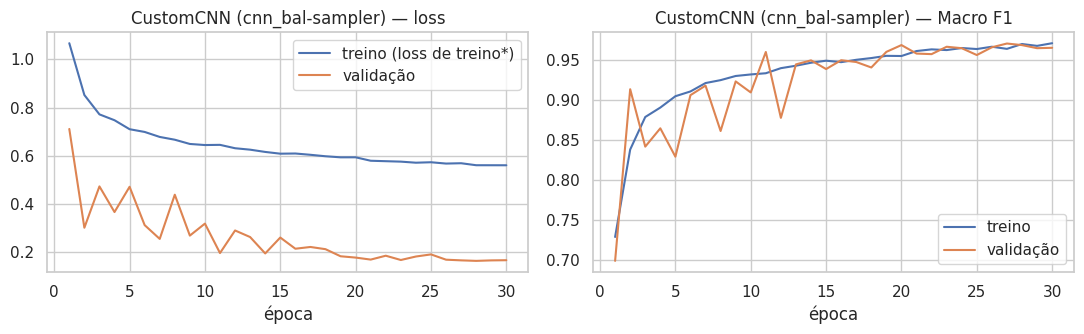

In [14]:
base_name = f"cnn_bal-{BEST_BALANCE}"
run_cnn("cnn_adamw-3e-3", BEST_BALANCE, "adamw", 3e-3)
run_cnn("cnn_sgd-0.05", BEST_BALANCE, "sgd", 0.05)

cand = pd.DataFrame(RUNS)
cand = cand[cand.run.isin([base_name, "cnn_adamw-3e-3", "cnn_sgd-0.05"])]
best_row = cand.loc[cand.val_macro_f1.idxmax()]
run_cnn("cnn_plateau", BEST_BALANCE, best_row.optim, best_row.lr, sched="plateau")

hp = pd.DataFrame(RUNS)
hp = hp[hp.run.isin([base_name, "cnn_adamw-3e-3", "cnn_sgd-0.05", "cnn_plateau"])]
display(hp[["run", "optim", "lr", "wd", "sched", "best_epoch", "epochs_run", "val_macro_f1", "train_time_s"]].round(4))

# Melhor CustomCNN entre TODAS as execuções (critério: validação)
all_cnn = pd.DataFrame(RUNS)
BEST_CNN = all_cnn.loc[all_cnn.val_macro_f1.idxmax(), "run"]
print("Melhor CustomCNN (validação):", BEST_CNN)
plot_history(HISTS[BEST_CNN], f"CustomCNN ({BEST_CNN})", "curvas_customcnn")

**Interpretação da busca de hiperparâmetros**

| Execução | Otimizador / LR | Scheduler | Melhor época | Macro F1 (validação) |
|---|---|---|---|---|
| `cnn_bal-sampler` (base) | AdamW 1e-3 | Cosine | 27/30 | **0,9704** |
| `cnn_adamw-3e-3` | AdamW 3e-3 | Cosine | 26/30 | 0,9703 |
| `cnn_sgd-0.05` | SGD+Nesterov 0,05 | Cosine | 26/30 | 0,9690 |
| `cnn_plateau` | AdamW 1e-3 | ReduceLROnPlateau | 27/30 | 0,9666 |

- **AdamW mostrou-se robusto ao learning rate:** triplicar o LR (1e-3 → 3e-3) praticamente não mudou o resultado. Isso é uma vantagem prática de otimizadores adaptativos.
- **SGD com momentum** ficou ligeiramente atrás (−0,0014): é competitivo, mas exigiria uma busca de LR mais fina.
- **Cosine Annealing superou ReduceLROnPlateau** (0,9704 × 0,9666). Com apenas 30 épocas e paciência de 3, o *plateau* reduz o LR em degraus e de forma reativa ao ruído da validação. O cosseno reduz o LR de forma suave e garantida até ~0, o que dá uma fase final de "refinamento" estável.
- A melhor CustomCNN é a **base (AdamW 1e-3, Cosine, sampler)**.

**Curvas de treino e overfitting:**
- No início, o F1 de validação oscila bastante (épocas 1–12), efeito do LR alto. À medida que o cosseno reduz o LR, as curvas se estabilizam e convergem.
- **Não há sinal de overfitting:** ao final, o Macro F1 de treino (≈0,97) e o de validação (≈0,97) praticamente coincidem, e a loss de validação continua caindo até as últimas épocas. As regularizações (augmentation, dropout, weight decay, label smoothing) cumpriram seu papel.
- O *early stopping* não chegou a ser acionado em nenhuma execução: as melhores épocas ficaram entre 24 e 27 de 30. Isso indica que o modelo ainda tirava proveito do final do treino; mais épocas poderiam render um pequeno ganho adicional.
- A ResNet18 apresentou o mesmo padrão: melhor época 16/20, F1 de treino 0,981 contra 0,976 na validação, ou seja, uma diferença pequena.

\* A loss de treino inclui label smoothing, augmentation e (se escolhido) pesos de classe, por isso não é diretamente comparável em valor absoluto à loss de validação (CE pura); o que importa é a tendência das curvas. É por isso que a curva de treino fica **acima** da de validação.

## 6. Transfer learning — ResNet18 pré-treinada

Mesmos dados, mesma estratégia de balanceamento e mesmas regularizações; otimizador AdamW com LR baixo (3e-4) e Cosine Annealing, típicos de *fine-tuning* (não reutilizamos o LR da CustomCNN porque pesos pré-treinados exigem passos menores).

[resnet18] ep 01 | train loss 0.8561 F1 0.8374 | val loss 0.2441 F1 0.9404 *
[resnet18] ep 02 | train loss 0.6654 F1 0.9190 | val loss 0.2289 F1 0.9462 *
[resnet18] ep 03 | train loss 0.6305 F1 0.9327 | val loss 0.2581 F1 0.9269 
[resnet18] ep 04 | train loss 0.6246 F1 0.9334 | val loss 0.1875 F1 0.9601 *
[resnet18] ep 05 | train loss 0.5982 F1 0.9467 | val loss 0.2046 F1 0.9491 
[resnet18] ep 06 | train loss 0.5876 F1 0.9522 | val loss 0.1792 F1 0.9620 *
[resnet18] ep 07 | train loss 0.5829 F1 0.9524 | val loss 0.1633 F1 0.9663 *
[resnet18] ep 08 | train loss 0.5790 F1 0.9550 | val loss 0.1988 F1 0.9539 
[resnet18] ep 09 | train loss 0.5678 F1 0.9592 | val loss 0.1732 F1 0.9636 
[resnet18] ep 10 | train loss 0.5609 F1 0.9631 | val loss 0.1698 F1 0.9677 *
[resnet18] ep 11 | train loss 0.5536 F1 0.9666 | val loss 0.1631 F1 0.9683 *
[resnet18] ep 12 | train loss 0.5471 F1 0.9669 | val loss 0.1598 F1 0.9701 *
[resnet18] ep 13 | train loss 0.5407 F1 0.9714 | val loss 0.1606 F1 0.9681 
[res

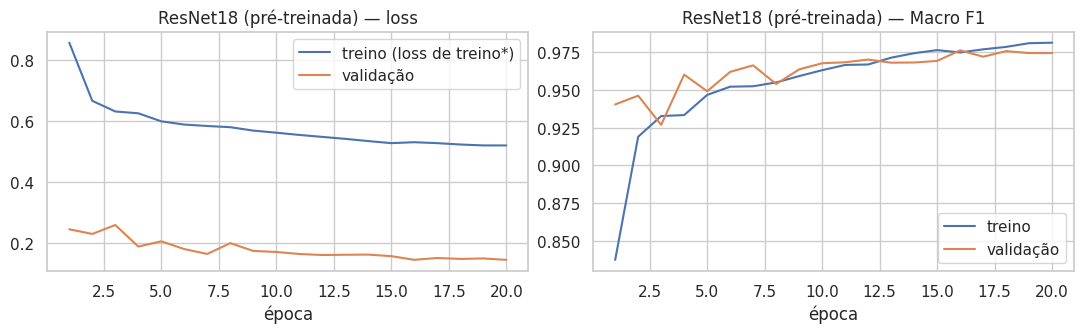

,run,model,balance,optim,lr,sched,best_epoch,val_macro_f1,train_time_s
0,cnn_bal-none,CustomCNN,none,adamw,0.0010,cosine,26,0.9696,520.8943
1,cnn_bal-weighted,CustomCNN,weighted,adamw,0.0010,cosine,24,0.9702,519.8346
2,cnn_bal-sampler,CustomCNN,sampler,adamw,0.0010,cosine,27,0.9704,522.6104
3,cnn_adamw-3e-3,CustomCNN,sampler,adamw,0.0030,cosine,26,0.9703,525.0810
4,cnn_sgd-0.05,CustomCNN,sampler,sgd,0.0500,cosine,26,0.9690,518.9177
5,cnn_plateau,CustomCNN,sampler,adamw,0.0010,plateau,27,0.9666,521.7578
6,resnet18,ResNet18,sampler,adamw,0.0003,cosine,16,0.9762,376.4727


In [15]:
seed_everything(CFG["seed"])
resnet, hist_r, s = fit(build_resnet18(), "resnet18", make_train_loader(BEST_BALANCE), make_loss(BEST_BALANCE),
                        optim="adamw", lr=CFG["resnet_lr"], wd=CFG["resnet_wd"], sched="cosine",
                        epochs=CFG["resnet_epochs"])
s.update(model="ResNet18", balance=BEST_BALANCE)
RUNS.append(s); MODELS["resnet18"] = resnet; HISTS["resnet18"] = hist_r
plot_history(hist_r, "ResNet18 (pré-treinada)", "curvas_resnet18")
pd.DataFrame(RUNS).to_csv(OUT / "todas_execucoes.csv", index=False)
display(pd.DataFrame(RUNS)[["run", "model", "balance", "optim", "lr", "sched", "best_epoch", "val_macro_f1", "train_time_s"]].round(4))

## 7. 📄 Resultados e métricas no teste oficial

**Seleção do modelo de submissão (somente pela validação):** comparamos a melhor CustomCNN e a ResNet18, cada uma com e sem TTA, no conjunto de **validação**; a configuração vencedora é a submetida ao ranking. Só depois disso o conjunto de **teste** é avaliado (os dois modelos são reportados no teste para comparação, mas a escolha já está feita).

In [16]:
candidates = {"CustomCNN": MODELS[BEST_CNN], "ResNet18": MODELS["resnet18"]}
sel = []
for mname, m in candidates.items():
    for tta in [False, True]:
        v = predict(m, val_loader, tta=tta)
        sel.append(dict(modelo=mname, tta=tta, val_macro_f1=v["macro_f1"], val_acc=v["acc"], val_loss=v["loss"]))
sel = pd.DataFrame(sel)
display(sel.round(4))
best_sel = sel.loc[sel.val_macro_f1.idxmax()]
SUB_MODEL, SUB_TTA = best_sel.modelo, bool(best_sel.tta)
print(f"➡ Submissão: {SUB_MODEL} | TTA={SUB_TTA}")

,modelo,tta,val_macro_f1,val_acc,val_loss
0,CustomCNN,False,0.9704,0.9731,0.1671
1,CustomCNN,True,0.9695,0.9720,0.1651
2,ResNet18,False,0.9762,0.9778,0.1441
3,ResNet18,True,0.9782,0.9784,0.1389


➡ Submissão: ResNet18 | TTA=True


In [17]:
@torch.no_grad()
def inference_time_per_batch(model, loader, tta=False, reps=3):
    """Tempo médio (ms) para inferir um batch de 128 imagens já na memória do dispositivo."""
    model.eval()
    batches = [x.to(DEVICE) for x, _ in loader]
    def run():
        for x in batches:
            with torch.autocast(device_type=DEVICE.type, enabled=USE_AMP):
                if tta:
                    torch.stack([F.softmax(model(dihedral(x, k)).float(), 1) for k in range(8)]).mean(0)
                else:
                    model(x)
    run()  # aquecimento
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps): run()
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / (reps * len(batches))

TEST = {}
rows = []
for mname, m in candidates.items():
    for tta in [False, True]:
        r = predict(m, test_loader, tta=tta)
        key = f"{mname}{' + TTA' if tta else ''}"
        TEST[key] = r
        rows.append(dict(modelo=key, test_macro_f1=r["macro_f1"], test_acc=r["acc"], test_loss=r["loss"],
                         ms_por_batch=inference_time_per_batch(m, test_loader, tta), parametros=n_params(m),
                         submissao=(mname == SUB_MODEL and tta == SUB_TTA)))
test_table = pd.DataFrame(rows)
test_table.to_csv(OUT / "resultados_teste.csv", index=False)
display(test_table.round(4))

SUB_KEY = f"{SUB_MODEL}{' + TTA' if SUB_TTA else ''}"
sub = TEST[SUB_KEY]
print(f"\n🏆 SUBMISSÃO ({SUB_KEY}) — Macro F1 teste: {sub['macro_f1']:.4f} | "
      f"Acurácia: {sub['acc']:.4f} | Test loss: {sub['loss']:.4f}")

,modelo,test_macro_f1,test_acc,test_loss,ms_por_batch,parametros,submissao
0,CustomCNN,0.9658,0.9693,0.1759,5.9407,1227080,False
1,CustomCNN + TTA,0.9702,0.9734,0.1715,47.2771,1227080,False
2,ResNet18,0.9710,0.9740,0.1545,26.1748,11180616,False
3,ResNet18 + TTA,0.9750,0.9775,0.1493,203.8393,11180616,True



🏆 SUBMISSÃO (ResNet18 + TTA) — Macro F1 teste: 0.9750 | Acurácia: 0.9775 | Test loss: 0.1493


### 7.1 Precision, Recall e F1 por classe (modelo de submissão)

In [18]:
def per_class_table(r):
    rep = classification_report(r["y"], r["preds"], labels=range(N_CLASSES), target_names=CLASSES, output_dict=True, zero_division=0)
    df = pd.DataFrame(rep).T.rename(columns={"precision": "Precision", "recall": "Recall", "f1-score": "F1", "support": "Suporte"})
    df["Suporte"] = df["Suporte"].astype(int)
    return df

rep_sub = per_class_table(sub)
rep_sub.to_csv(OUT / "relatorio_por_classe_submissao.csv")
display(rep_sub.round(4))

,Precision,Recall,F1,Suporte
Basófilo,0.9797,0.9877,0.9837,244
Eosinófilo,0.9984,0.9984,0.9984,624
Eritroblasto,0.9967,0.9582,0.9770,311
Granulócito imaturo,0.9441,0.9620,0.9530,579
Linfócito,0.9339,0.9877,0.9600,243
Monócito,0.9472,0.9472,0.9472,284
Neutrófilo,0.9923,0.9700,0.9810,666
Plaqueta,1.0000,1.0000,1.0000,470
accuracy,0.9775,0.9775,0.9775,0
macro avg,0.9740,0.9764,0.9750,3421


### 7.2 Matriz de confusão (modelo de submissão)

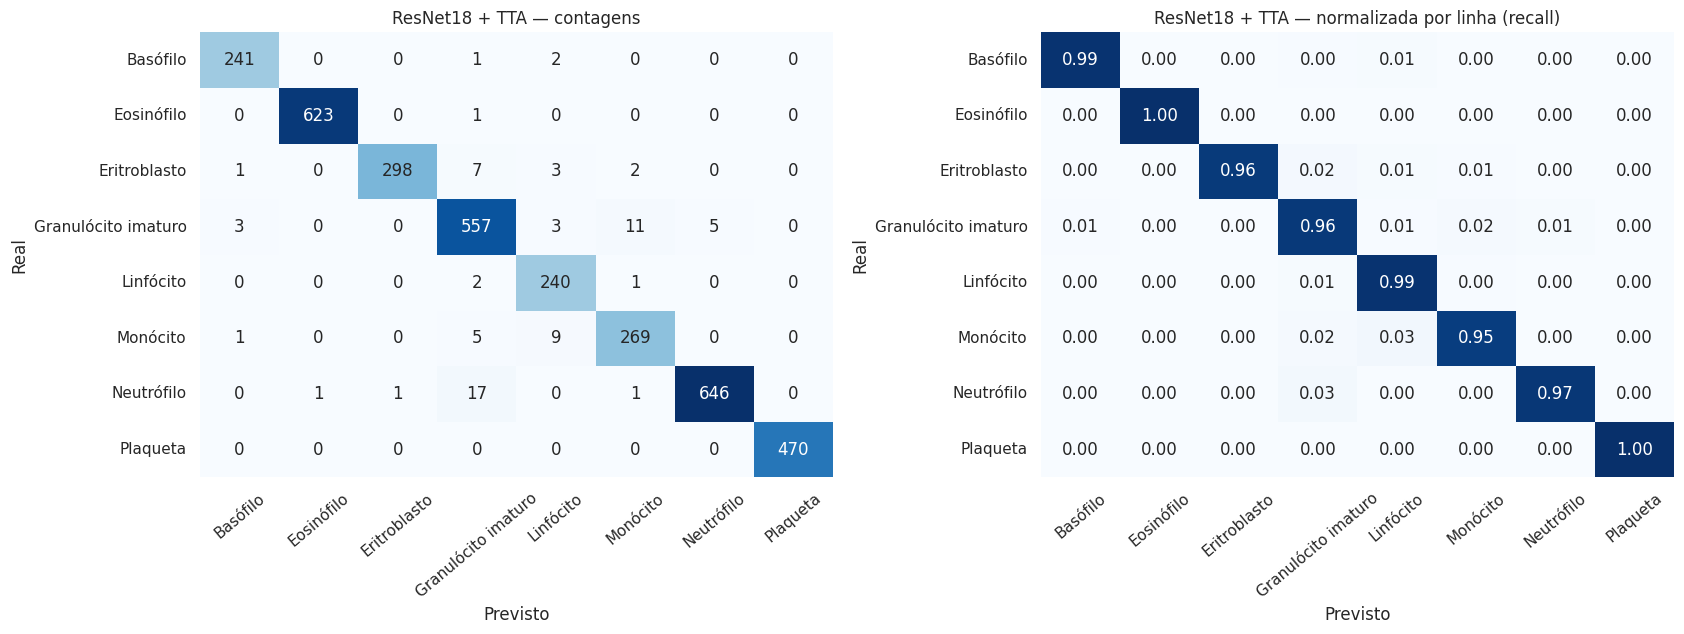

In [19]:
def plot_confusion(r, title, fname):
    cm = confusion_matrix(r["y"], r["preds"], labels=range(N_CLASSES))
    cmn = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(17, 6.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False, vmin=0, vmax=1)
    ax[0].set_title(f"{title} — contagens"); ax[1].set_title(f"{title} — normalizada por linha (recall)")
    for a in ax:
        a.set_xlabel("Previsto"); a.set_ylabel("Real"); a.tick_params(axis="x", rotation=40)
    plt.tight_layout(); plt.savefig(OUT / f"figures/{fname}.png", dpi=150); plt.show()
    return cm

cm_sub = plot_confusion(sub, SUB_KEY, "matriz_confusao_submissao")

### 7.3 Comparação CustomCNN × ResNet18 por classe (F1 no teste)

,CustomCNN,ResNet18
Basófilo,0.9669,0.9692
Eosinófilo,0.9960,0.9960
Eritroblasto,0.9696,0.9737
Granulócito imaturo,0.9312,0.9446
Linfócito,0.9539,0.9598
Monócito,0.9305,0.9437
Neutrófilo,0.9791,0.9811
Plaqueta,0.9989,1.0000
Macro F1,0.9658,0.9710


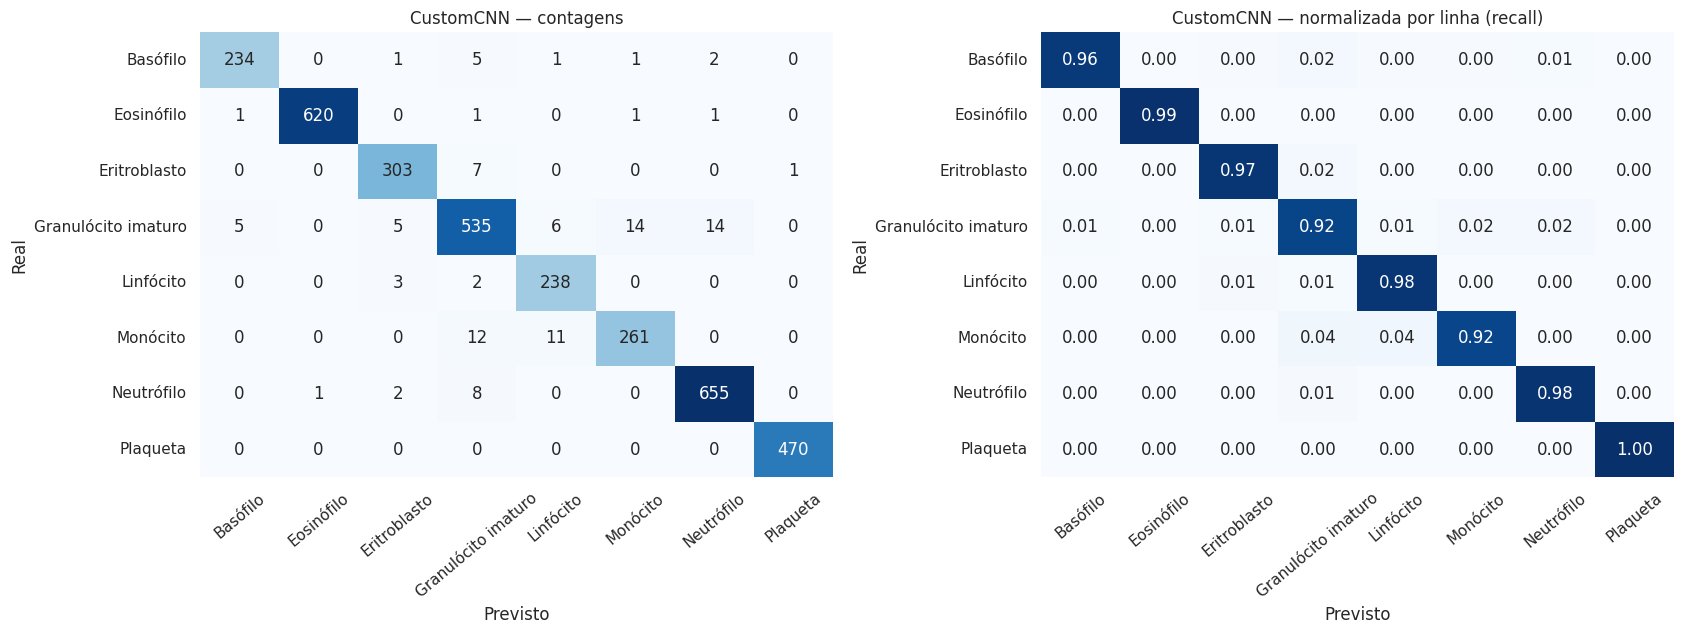

In [20]:
cmp = pd.DataFrame({k: per_class_table(TEST[k]).loc[CLASSES, "F1"] for k in ["CustomCNN", "ResNet18"]})
cmp.loc["Macro F1"] = [TEST["CustomCNN"]["macro_f1"], TEST["ResNet18"]["macro_f1"]]
display(cmp.round(4))
other = "CustomCNN" if SUB_MODEL == "ResNet18" else "ResNet18"
_ = plot_confusion(TEST[other], other, f"matriz_confusao_{other.lower()}")

**Discussão dos resultados**

| Modelo | Macro F1 (val) | **Macro F1 (teste)** | Acurácia (teste) | Test loss | ms/batch (T4) | Parâmetros |
|---|---|---|---|---|---|---|
| CustomCNN | 0,9704 | 0,9658 | 0,9693 | 0,1759 | 5,9 | 1,2 M |
| CustomCNN + TTA | 0,9695 | 0,9702 | 0,9734 | 0,1715 | 47,3 | 1,2 M |
| ResNet18 | 0,9762 | 0,9710 | 0,9740 | 0,1545 | 26,2 | 11,2 M |
| **ResNet18 + TTA (submissão)** | **0,9782** | **0,9750** | **0,9775** | **0,1493** | 203,8 | 11,2 M |

**Submissão ao ranking: ResNet18 + TTA, com Macro F1 = 0,9750 no teste oficial** (test loss 0,1493; 203,8 ms por batch de 128 imagens numa GPU T4). A escolha foi feita pela validação, onde essa configuração também foi a melhor (0,9782), e o teste confirmou a mesma ordem entre os modelos.

- **Transfer learning compensou:** a ResNet18 superou ou empatou com a CustomCNN em todas as classes (empate apenas no Eosinófilo). O ganho é de +0,005 de Macro F1 sem TTA e +0,005 com TTA. Os filtros aprendidos no ImageNet, somados ao *upsampling* para 128×128, permitem extrair mais detalhe de textura do núcleo e do citoplasma.
- **A CustomCNN é uma alternativa muito eficiente:** com 9× menos parâmetros e ~4× mais rápida na inferência, fica apenas 0,005 abaixo. Em um cenário de triagem com hardware limitado, ela seria uma escolha defensável.
- **TTA** melhorou ambos os modelos no teste (+0,004 a +0,005). O custo é multiplicar o tempo de inferência por 8, o que só pesaria no ranking como critério de desempate.
- **Macro F1 (0,9750) ≈ acurácia (0,9775):** se o modelo errasse muito nas classes raras, o Macro F1 ficaria bem abaixo da acurácia. A proximidade das duas métricas mostra que o desempenho é **homogêneo entre as classes**, que é exatamente o objetivo do tratamento de desbalanceamento.
- **Por classe:**
  - Plaqueta (F1 = 1,000) e Eosinófilo (0,998) são praticamente perfeitas, porque têm morfologia muito distinta: a plaqueta é pequena e sem núcleo, e o eosinófilo tem grânulos alaranjados característicos.
  - As classes mais difíceis são **Monócito (0,947)**, **Granulócito imaturo (0,953)** e **Linfócito (0,960)**.
  - No Linfócito, o *recall* é alto (0,988), mas a *precision* é a menor de todas (0,934): o modelo raramente perde um linfócito, mas às vezes chama outras células de linfócito (ver seção 8).
- Como referência, o artigo do MedMNIST v2 reporta acurácia de ~0,96 para a ResNet18 no BloodMNIST. Nosso modelo (0,9775 de acurácia) ficou acima dessa linha de base.

## 8. 📄 Discussão de erros

,Real,Previsto como,Qtd,% da classe real
18,Neutrófilo,Granulócito imaturo,17,0.026
9,Granulócito imaturo,Monócito,11,0.019
15,Monócito,Linfócito,9,0.032
4,Eritroblasto,Granulócito imaturo,7,0.023
10,Granulócito imaturo,Neutrófilo,5,0.009
14,Monócito,Granulócito imaturo,5,0.018
8,Granulócito imaturo,Linfócito,3,0.005
5,Eritroblasto,Linfócito,3,0.010


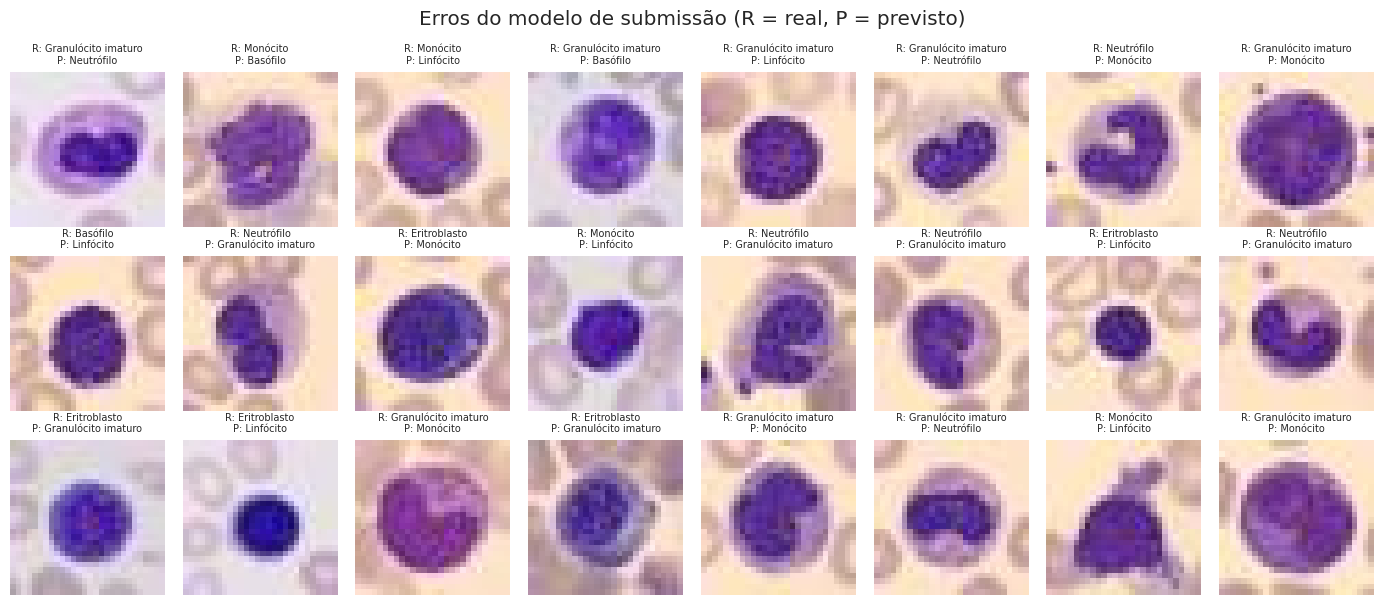

In [21]:
off = [(CLASSES[i], CLASSES[j], int(cm_sub[i, j]), cm_sub[i, j] / cm_sub[i].sum())
       for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm_sub[i, j] > 0]
pairs = pd.DataFrame(off, columns=["Real", "Previsto como", "Qtd", "% da classe real"]).sort_values("Qtd", ascending=False)
display(pairs.head(8).round(3))

# Exemplos de erros do modelo de submissão
wrong = np.where(sub["preds"] != sub["y"])[0]
show = wrong[np.random.default_rng(CFG["seed"]).permutation(len(wrong))[:24]] if len(wrong) else []
if len(show):
    fig, axes = plt.subplots(3, 8, figsize=(14, 6.2))
    for a in axes.ravel(): a.axis("off")
    for a, i in zip(axes.ravel(), show):
        a.imshow(Xte[i])
        a.set_title(f"R: {CLASSES[sub['y'][i]]}\nP: {CLASSES[sub['preds'][i]]}", fontsize=7)
    plt.suptitle("Erros do modelo de submissão (R = real, P = previsto)"); plt.tight_layout()
    plt.savefig(OUT / "figures/exemplos_erros.png", dpi=150); plt.show()

**Discussão de erros**

O modelo de submissão errou **77 das 3.421** imagens de teste (2,25%). Os erros se concentram em poucos pares de classes, quase todos envolvendo **Granulócito imaturo**:

1. **Neutrófilo → Granulócito imaturo (17 casos, o par mais frequente).** Os granulócitos imaturos (promielócitos, mielócitos e metamielócitos) são **precursores dos neutrófilos**: a maturação é um processo contínuo, em que o núcleo vai de arredondado a "em forma de rim" (metamielócito), depois "em bastão" e por fim segmentado (neutrófilo maduro). Um metamielócito e um neutrófilo jovem (bastonete) estão literalmente lado a lado nesse contínuo; mesmo hematologistas divergem na fronteira. Nas imagens de erro vê-se justamente neutrófilos com núcleo pouco segmentado, em forma de "C" ou de rim. O caminho inverso (GI → Neutrófilo, 5 casos) é menos frequente.
2. **Granulócito imaturo → Monócito (11) e Monócito → Granulócito imaturo (5).** Ambos são células grandes, com núcleo volumoso e irregular/endentado e citoplasma azul-acinzentado. O que os distingue é a **granulação fina do citoplasma** e a textura da cromatina, detalhes que ocupam 1–2 pixels numa imagem de 28×28 e são em grande parte perdidos na redução de resolução.
3. **Monócito → Linfócito (9, ou 3,2% dos monócitos).** Monócitos pequenos, com núcleo arredondado e pouco citoplasma visível, se parecem com linfócitos grandes. Isso explica a *precision* mais baixa do Linfócito.
4. **Eritroblasto → Granulócito imaturo (7) / Linfócito (3).** O eritroblasto (hemácia nucleada) tem núcleo redondo e muito denso, parecido com o de um linfócito, e citoplasma de cor variável conforme o estágio de maturação.

**Padrões gerais:**
- Os erros acontecem entre células de **morfologia semelhante e biologicamente relacionadas**, e não entre classes muito diferentes. Por exemplo, nenhuma plaqueta foi confundida com qualquer outra classe. Isso indica que o modelo aprendeu características relevantes, e não atalhos espúrios.
- Algumas imagens de erro contêm **células vizinhas ou cortadas na borda**, ou têm coloração atípica, o que dificulta a tarefa. É possível que parte dos casos seja ruído de rotulagem, comum em datasets de hematologia justamente nas classes de fronteira.
- **Clinicamente**, confundir neutrófilos com granulócitos imaturos é o erro mais relevante: o aumento de granulócitos imaturos no sangue periférico ("desvio à esquerda") é um marcador de infecção. Num uso real, as células classificadas como GI com baixa confiança deveriam ser revisadas por um especialista.
- **Caminhos de melhoria:**
  - Usar resolução maior: o MedMNIST+ oferece o BloodMNIST em 64, 128 e 224 px, o que preservaria a granulação.
  - Fazer um *ensemble* CustomCNN + ResNet18.
  - Treinar por mais épocas.

## 9. 📄 Conclusão

- Construímos um pipeline reproduzível de ponta a ponta para o BloodMNIST: download oficial via `medmnist`, splits oficiais, seed fixa e seleção de modelos **exclusivamente pela validação**. Nele, comparamos uma **CNN residual própria** e uma **ResNet18 pré-treinada**.
- **Resultado oficial: Macro F1 = 0,9750 no teste** (acurácia 0,9775, test loss 0,1493), com ResNet18 + TTA. A CustomCNN, com 9× menos parâmetros, alcançou 0,9658 (0,9702 com TTA).
- **Balanceamento:** com desbalanceamento moderado (2,7×), *WeightedRandomSampler* e CE ponderada trouxeram ganhos pequenos sobre a linha de base. O resultado final mostra desempenho homogêneo: Macro F1 próximo da acurácia e as classes raras com *recall* de 0,988.
- **Otimização:** AdamW + Cosine Annealing foi a melhor combinação. AdamW se mostrou pouco sensível ao LR, e o cosseno superou o ReduceLROnPlateau. As regularizações evitaram overfitting: as curvas de treino e validação convergiram juntas.
- **Erros:** concentram-se entre Neutrófilo, Granulócito imaturo e Monócito, classes com morfologia semelhante e, no primeiro par, biologicamente contínuas. A baixa resolução de 28×28 apaga os detalhes de granulação que as diferenciariam.

**Limitações:**
- Cada configuração foi treinada com uma única seed, então as diferenças da ordem de 0,001 não são estatisticamente conclusivas.
- A resolução de 28×28 limita o desempenho nas classes de fronteira.
- O TTA multiplica por 8 o custo de inferência.

**Trabalhos futuros:**
- Repetir os experimentos com várias seeds e reportar média ± desvio.
- Usar as versões de maior resolução do MedMNIST+.
- Testar um *ensemble* dos dois modelos.

In [22]:
summary = dict(
    submissao=SUB_KEY,
    test_macro_f1=float(sub["macro_f1"]), test_acc=float(sub["acc"]), test_loss=float(sub["loss"]),
    ms_por_batch=float(test_table.loc[test_table.submissao, "ms_por_batch"].iloc[0]),
    melhor_balanceamento=BEST_BALANCE, melhor_cnn=BEST_CNN,
    dispositivo=str(DEVICE), modo_rapido=CFG["quick"], cfg={k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()},
)
(OUT / "resumo.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary, indent=2, ensure_ascii=False))

# No Colab: compacta a pasta outputs/ e baixa automaticamente
if IN_COLAB:
    shutil.make_archive("outputs", "zip", "outputs")
    from google.colab import files
    files.download("outputs.zip")

{
  "submissao": "ResNet18 + TTA",
  "test_macro_f1": 0.9750339860642725,
  "test_acc": 0.977491961414791,
  "test_loss": 0.1492806077003479,
  "ms_por_batch": 203.83934223456643,
  "melhor_balanceamento": "sampler",
  "melhor_cnn": "cnn_bal-sampler",
  "dispositivo": "cuda",
  "modo_rapido": false,
  "cfg": {
    "quick": false,
    "seed": 42,
    "batch_size": 128,
    "num_workers": 2,
    "cnn_epochs": 30,
    "cnn_widths": [
      64,
      128,
      256
    ],
    "cnn_dropout": 0.3,
    "resnet_epochs": 20,
    "resnet_img_size": 128,
    "resnet_lr": 0.0003,
    "resnet_wd": 0.05,
    "label_smoothing": 0.1,
    "patience": 8,
    "quick_train": 600,
    "quick_eval": 300
  }
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>